# 03 — GMM parameter investigation

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*  
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495)

## 1. Objective

Notebook 02 already produced frame-level modified cepstral features from labelled calls. This notebook continues with the modelling stage described mainly in Sections **3.5, 3.6 and 4.1** of the paper:

**processed call features → one GMM per species → call-level likelihood scoring → species prediction → per-species error → WER → parameter investigation**

The experiment follows the paper's GMM grid:

- training material per species: **6, 12 and 18 seconds**;
- Gaussian components: **2, 4, 8, 16, 32 and 64**;
- ten repeated random selections.

**Important source discrepancy:** the current processed artifacts contain **20 modified-filterbank cepstral coefficients (m-FCC)**, which directly support the paper's 20 m-FCC model-order experiment (Table 2). The paper's Figure 8, however, is labelled **12 MFCC** and Section 4.1 refers to 12-dimensional mel-cepstral vectors. Therefore the 6/12/18-second plot produced here is a replication of the **GMM experimental protocol on the recovered 20 m-FCC features**, not a claim of exact feature-level reproduction of Figure 8.

This notebook stops after the GMM identification experiment. Likelihood-ratio verification, ROC thresholds and presence/absence estimation belong to the next stage.

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.mixture import GaussianMixture

sns.set_theme(style="ticks")
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
PROCESSED_DIR = REPO_ROOT / "data" / "processed"

FEATURES_PATH = PROCESSED_DIR / "features.npy"
LABELS_PATH = PROCESSED_DIR / "labels.npy"
CALLS_PATH = PROCESSED_DIR / "calls.csv"

for path in (FEATURES_PATH, LABELS_PATH, CALLS_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run notebooks/02_preprocessing.ipynb first.")

print("Repository root:", REPO_ROOT)
print("Processed dir :", PROCESSED_DIR)

Repository root: C:\Users\sofia\Projects\PUCE\frog-presence-replication
Processed dir : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed


## 2. Load and validate processed artifacts

`features.npy` contains one row per frame, `labels.npy` the corresponding species code, and `calls.csv` one row per call with the number of frames contributed by that call.

In [3]:
features = np.load(FEATURES_PATH)
labels = np.load(LABELS_PATH)
calls = pd.read_csv(CALLS_PATH)

print("features:", features.shape, features.dtype)
print("labels  :", labels.shape, labels.dtype)
print("calls   :", calls.shape)
display(calls.head())

required = {"code", "species", "seconds", "frames"}
missing = required - set(calls.columns)
if missing:
    raise ValueError(f"calls.csv is missing required columns: {sorted(missing)}")

assert features.ndim == 2
assert features.shape[1] == 20, f"Expected 20 features, got {features.shape[1]}"
assert len(features) == len(labels)
assert int(calls["frames"].sum()) == len(features)

print("Alignment checks passed.")

features: (136005, 20) float64
labels  : (136005,) <U3
calls   : (1461, 7)


,code,species,wav,recording,rate,seconds,frames
0,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73
1,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73
2,f01,Boana alfaroi,1101.WAV,0,44100,0.42,81
3,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93
4,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93


Alignment checks passed.


## 3. Reconstruct complete calls

The call, not the frame, is the unit of train/validation separation. Frames from the same call must never appear on both sides of a split.

In [4]:
calls = calls.copy().reset_index(drop=True)
calls["call_id"] = [f"call_{i:04d}" for i in range(len(calls))]
calls["frame_stop"] = calls["frames"].cumsum().astype(int)
calls["frame_start"] = calls["frame_stop"].shift(fill_value=0).astype(int)
CALLS_BY_ID = calls.set_index("call_id", drop=False)

def get_call_features(call_id: str) -> np.ndarray:
    row = CALLS_BY_ID.loc[call_id]
    return features[int(row.frame_start):int(row.frame_stop)]

bad = []
for row in calls.itertuples(index=False):
    block = labels[int(row.frame_start):int(row.frame_stop)]
    if len(block) != int(row.frames) or not np.all(block == row.code):
        bad.append(row.call_id)

if bad:
    raise AssertionError(f"Call reconstruction failed for {len(bad)} calls: {bad[:5]}")

species_inventory = (
    calls.groupby(["code", "species"], as_index=False)
    .agg(calls=("call_id", "size"), seconds=("seconds", "sum"), frames=("frames", "sum"))
    .sort_values("code")
)
species_inventory["seconds"] = species_inventory["seconds"].round(2)

display(species_inventory)
print("Reconstructed calls:", len(calls))

,code,species,calls,seconds,frames
0,f01,Boana alfaroi,98,44.72,8650
1,f02,Dendropsophus bifurcus,99,41.72,8047
2,f03,Boana cinerascens,169,102.58,20009
3,f04,Pristimantis conspicillatus,186,77.94,15030
4,f05,Leptodactylus discodactylus,340,114.36,21852
5,f06,Osteocephalus fuscifacies,54,24.94,4826
6,f07,Boana lanciformis,101,57.84,11265
7,f08,Rhinella margaritifera,96,102.66,20244
8,f09,Dendropsophus parviceps,2,1.18,230
9,f10,Engystomops petersi,316,134.00,25852


Reconstructed calls: 1461


## 4. Species usable in the experiment

`[PAPER]` Section 4.1 uses 6, 12 and 18 seconds per species.  
`[REPLICATION DECISION]` We include every recovered species with enough material to support the largest training condition while still leaving validation calls. This is determined from the artifacts rather than hard-coded.

In [5]:
TRAINING_DURATIONS = (6, 12, 18)
N_COMPONENTS_GRID = (2, 4, 8, 16, 32, 64)
N_REPEATS = 10
BASE_SEED = 20260814

usable_inventory = species_inventory[species_inventory["seconds"] > max(TRAINING_DURATIONS)].copy()
USABLE_CODES = tuple(usable_inventory["code"])
excluded_inventory = species_inventory[~species_inventory["code"].isin(USABLE_CODES)].copy()

print("Usable species:", USABLE_CODES)
print("\nIncluded:")
display(usable_inventory)
print("\nExcluded:")
display(excluded_inventory)

Usable species: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')

Included:


,code,species,calls,seconds,frames
0,f01,Boana alfaroi,98,44.72,8650
1,f02,Dendropsophus bifurcus,99,41.72,8047
2,f03,Boana cinerascens,169,102.58,20009
3,f04,Pristimantis conspicillatus,186,77.94,15030
4,f05,Leptodactylus discodactylus,340,114.36,21852
5,f06,Osteocephalus fuscifacies,54,24.94,4826
6,f07,Boana lanciformis,101,57.84,11265
7,f08,Rhinella margaritifera,96,102.66,20244
9,f10,Engystomops petersi,316,134.00,25852



Excluded:


,code,species,calls,seconds,frames
8,f09,Dendropsophus parviceps,2,1.18,230


## 5. Select whole calls until the duration target is reached

`[PAPER]` The paper selects 6, 12 or 18 seconds for training and uses the remaining calls for validation.

`[REPLICATION DECISION]` Because the paper does not specify how variable call durations are combined, this notebook shuffles whole calls reproducibly and takes the shortest random prefix whose cumulative duration reaches or exceeds the target. Calls are never cut merely to hit an exact duration, and at least one validation call must remain.

In [ ]:
def _species_number(code: str) -> int:
    digits = "".join(ch for ch in str(code) if ch.isdigit())
    return int(digits) if digits else 0


def select_training_calls(calls_df, code, target_seconds, seed, max_attempts=100):
    subset = calls_df.loc[calls_df["code"] == code].copy().reset_index(drop=True)
    if subset["seconds"].sum() <= target_seconds:
        raise ValueError(f"{code} does not have enough material for {target_seconds}s + validation.")

    for attempt in range(max_attempts):
        rng = np.random.default_rng(seed + attempt)
        order = rng.permutation(len(subset))
        selected, total = [], 0.0

        for pos in order:
            selected.append(subset.iloc[pos]["call_id"])
            total += float(subset.iloc[pos]["seconds"])
            if total >= target_seconds:
                break

        if total >= target_seconds and len(selected) < len(subset):
            selected = tuple(selected)
            selected_set = set(selected)
            validation = tuple(cid for cid in subset["call_id"] if cid not in selected_set)
            return {
                "train_ids": selected,
                "validation_ids": validation,
                "actual_seconds": float(total),
                "overshoot_seconds": float(total - target_seconds),
                "n_train_calls": len(selected),
                "n_validation_calls": len(validation),
            }

    raise RuntimeError(f"Could not build a valid split for {code} at {target_seconds}s.")


def build_split(target_seconds, repeat):
    train_ids, validation_ids, rows = {}, {}, []

    for code in USABLE_CODES:
        seed = BASE_SEED + repeat * 10_000 + int(target_seconds) * 100 + _species_number(code)
        split = select_training_calls(calls, code, target_seconds, seed)
        train_ids[code] = split["train_ids"]
        validation_ids[code] = split["validation_ids"]

        rows.append({
            "code": code,
            "species": CALLS_BY_ID.loc[split["train_ids"][0], "species"],
            "training_seconds_target": target_seconds,
            "training_seconds_actual": split["actual_seconds"],
            "overshoot_seconds": split["overshoot_seconds"],
            "n_train_calls": split["n_train_calls"],
            "n_validation_calls": split["n_validation_calls"],
            "repeat": repeat,
            "seed": seed,
        })

    for code in USABLE_CODES:
        assert not (set(train_ids[code]) & set(validation_ids[code])), f"Leakage in {code}"

    return train_ids, validation_ids, pd.DataFrame(rows)


demo_train_ids, demo_validation_ids, demo_split = build_split(12, 0)
display(demo_split[["code", "training_seconds_target", "training_seconds_actual", "overshoot_seconds", "n_train_calls", "n_validation_calls"]])

# Reproducibility test.
demo_train_ids_2, demo_validation_ids_2, _ = build_split(12, 0)
assert demo_train_ids == demo_train_ids_2
assert demo_validation_ids == demo_validation_ids_2
print("Split reproducibility check passed.")

,code,training_seconds_target,training_seconds_actual,overshoot_seconds,n_train_calls,n_validation_calls
0,f01,12,12.10,0.10,26,72
1,f02,12,12.08,0.08,28,71
2,f03,12,12.60,0.60,19,150
3,f04,12,12.22,0.22,30,156
4,f05,12,12.18,0.18,35,305
5,f06,12,12.46,0.46,27,27
6,f07,12,12.54,0.54,23,78
7,f08,12,12.66,0.66,11,85
8,f10,12,12.22,0.22,29,287


Split reproducibility check passed.


## 6. Train one diagonal-covariance GMM per species

`[PAPER]` The paper specifies EM / maximum likelihood, diagonal covariance, k-means++ initialization of means, uniform initial mixture weights, and initial diagonal variances equal to the variance of each feature dimension.

The initialization below supplies those quantities explicitly to `GaussianMixture`. A small `reg_covar` is retained for numerical stability and documented as an implementation detail not specified by the article.

In [14]:
def make_initial_parameters(X, n_components, seed):
    if len(X) < n_components:
        raise ValueError(f"Need at least {n_components} frames, got {len(X)}")

    means_init, _ = kmeans_plusplus(X, n_clusters=n_components, random_state=seed)
    variance = np.maximum(np.var(X, axis=0, ddof=0), 1e-12)
    weights_init = np.full(n_components, 1.0 / n_components)
    precisions_init = np.tile(1.0 / variance, (n_components, 1))
    return weights_init, means_init, precisions_init


def fit_one_gmm(X_train, n_components, seed):
    weights_init, means_init, precisions_init = make_initial_parameters(X_train, n_components, seed)

    model = GaussianMixture(
        n_components=n_components,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=100,
        tol=1e-3,
        init_params="random",  # all parameter families are provided explicitly above
    )

    with warnings.catch_warnings():
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train)
    return model


def stack_call_features(call_ids):
    return np.vstack([get_call_features(cid) for cid in call_ids])


def fit_species_models(train_ids_by_code, n_components, target_seconds, repeat):
    models = {}
    for code in USABLE_CODES:
        X_train = stack_call_features(train_ids_by_code[code])
        seed = (BASE_SEED + repeat * 1_000_000 + int(target_seconds) * 10_000 + n_components * 100 + _species_number(code))
        models[code] = fit_one_gmm(X_train, n_components, seed)
    return models

## 7. Classify a complete call by average log-likelihood

`[PAPER]` Equation 9 classifies a call with the species model that maximizes the average frame log-likelihood. `score_samples()` is therefore averaged across all frames of the call. We do **not** classify frames independently with `predict()`.

In [16]:
def score_call(X_call, models):
    return {code: float(model.score_samples(X_call).mean()) for code, model in models.items()}


def predict_call(call_id, models):
    scores = score_call(get_call_features(call_id), models)
    predicted = max(scores, key=scores.get)
    return predicted, scores


demo_models = fit_species_models(demo_train_ids, n_components=2, target_seconds=12, repeat=0)
example_true = USABLE_CODES[0]
example_id = demo_validation_ids[example_true][0]
example_pred, example_scores = predict_call(example_id, demo_models)

print("Call      :", example_id)
print("True code :", example_true)
print("Prediction:", example_pred)
display(pd.Series(example_scores, name="mean_log_likelihood").sort_values(ascending=False).to_frame())

Call      : call_0000
True code : f01
Prediction: f01


,mean_log_likelihood
f01,-40.293595
f05,-47.851856
f06,-48.888467
f03,-49.016555
f02,-49.662071
f10,-52.145369
f04,-52.196830
f07,-55.742525
f08,-68.529623


## 8. Per-species error and WER

The article averages the individual species error rates so the unbalanced classes have equal influence.

\[
error_s = 
rac{incorrect_s}{validation_s}, \qquad WER = mean_s(error_s)
\]

In [17]:
def evaluate_models(models, validation_ids_by_code, split_summary, n_components, target_seconds, repeat):
    prediction_rows, species_rows = [], []
    split_by_code = split_summary.set_index("code")

    for true_code in USABLE_CODES:
        validation_ids = validation_ids_by_code[true_code]
        correct = 0

        for call_id in validation_ids:
            predicted, scores = predict_call(call_id, models)
            ok = predicted == true_code
            correct += int(ok)
            prediction_rows.append({
                "training_seconds_target": target_seconds,
                "n_components": n_components,
                "repeat": repeat,
                "call_id": call_id,
                "true_code": true_code,
                "predicted_code": predicted,
                "correct": ok,
                "winning_score": scores[predicted],
                "true_model_score": scores[true_code],
            })

        n_validation = len(validation_ids)
        incorrect = n_validation - correct
        s = split_by_code.loc[true_code]
        species_rows.append({
            "training_seconds_target": target_seconds,
            "training_seconds_actual": float(s.training_seconds_actual),
            "overshoot_seconds": float(s.overshoot_seconds),
            "n_components": n_components,
            "repeat": repeat,
            "code": true_code,
            "species": s.species,
            "n_train_calls": int(s.n_train_calls),
            "n_validation_calls": n_validation,
            "correct": correct,
            "incorrect": incorrect,
            "error_rate": incorrect / n_validation,
        })

    per_species = pd.DataFrame(species_rows)
    predictions = pd.DataFrame(prediction_rows)
    wer = float(per_species["error_rate"].mean())
    return per_species, predictions, wer


demo_per_species, demo_predictions, demo_wer = evaluate_models(
    demo_models, demo_validation_ids, demo_split, n_components=2, target_seconds=12, repeat=0
)
display(demo_per_species[["code", "n_validation_calls", "correct", "incorrect", "error_rate"]])
print("Demo WER:", round(demo_wer * 100, 3), "%")
assert np.isclose(demo_wer, demo_per_species["error_rate"].mean())

,code,n_validation_calls,correct,incorrect,error_rate
0,f01,72,72,0,0.000000
1,f02,71,64,7,0.098592
2,f03,150,144,6,0.040000
3,f04,156,156,0,0.000000
4,f05,305,304,1,0.003279
5,f06,27,27,0,0.000000
6,f07,78,78,0,0.000000
7,f08,85,85,0,0.000000
8,f10,287,285,2,0.006969


Demo WER: 1.654 %


## 9. Full parameter experiment

`[PAPER]` The text says “10-fold cross-validation with random segment selection”, but does not fully specify a conventional mutually-exclusive K-fold procedure together with the fixed 6/12/18-second training conditions.

`[REPLICATION DECISION]` We therefore perform **10 reproducible random call selections per training duration**. Within one duration/repeat, the exact same train/validation split is reused across all six model orders so that only `M` changes.

In [18]:
def run_condition(target_seconds, n_components, repeat, train_ids, validation_ids, split_summary):
    models = fit_species_models(train_ids, n_components, target_seconds, repeat)
    per_species, predictions, wer = evaluate_models(
        models, validation_ids, split_summary, n_components, target_seconds, repeat
    )
    wer_row = {
        "training_seconds_target": target_seconds,
        "n_components": n_components,
        "repeat": repeat,
        "WER": wer,
        "WER_percent": wer * 100,
    }
    return per_species, predictions, wer_row


RUN_FULL_EXPERIMENT = True
STORE_CALL_PREDICTIONS = True

per_species_blocks = []
wer_rows = []
prediction_blocks = []

if RUN_FULL_EXPERIMENT:
    for target_seconds in TRAINING_DURATIONS:
        for repeat in range(N_REPEATS):
            train_ids, validation_ids, split_summary = build_split(target_seconds, repeat)
            print(f"duration={target_seconds:>2}s | repeat={repeat + 1:>2}/{N_REPEATS}")

            for n_components in N_COMPONENTS_GRID:
                per_species, predictions, wer_row = run_condition(
                    target_seconds, n_components, repeat,
                    train_ids, validation_ids, split_summary
                )
                per_species_blocks.append(per_species)
                wer_rows.append(wer_row)
                if STORE_CALL_PREDICTIONS:
                    prediction_blocks.append(predictions)

    per_species_results = pd.concat(per_species_blocks, ignore_index=True)
    wer_results = pd.DataFrame(wer_rows)
    call_predictions = (
        pd.concat(prediction_blocks, ignore_index=True)
        if STORE_CALL_PREDICTIONS else pd.DataFrame()
    )

    print("\nExperimental grid complete.")
else:
    print("Full experiment skipped because RUN_FULL_EXPERIMENT=False")

duration= 6s | repeat= 1/10
duration= 6s | repeat= 2/10
duration= 6s | repeat= 3/10
duration= 6s | repeat= 4/10
duration= 6s | repeat= 5/10
duration= 6s | repeat= 6/10
duration= 6s | repeat= 7/10
duration= 6s | repeat= 8/10
duration= 6s | repeat= 9/10
duration= 6s | repeat=10/10
duration=12s | repeat= 1/10
duration=12s | repeat= 2/10
duration=12s | repeat= 3/10
duration=12s | repeat= 4/10
duration=12s | repeat= 5/10
duration=12s | repeat= 6/10
duration=12s | repeat= 7/10
duration=12s | repeat= 8/10
duration=12s | repeat= 9/10
duration=12s | repeat=10/10
duration=18s | repeat= 1/10
duration=18s | repeat= 2/10
duration=18s | repeat= 3/10
duration=18s | repeat= 4/10
duration=18s | repeat= 5/10
duration=18s | repeat= 6/10
duration=18s | repeat= 7/10
duration=18s | repeat= 8/10
duration=18s | repeat= 9/10
duration=18s | repeat=10/10

Experimental grid complete.


## 10. Experiment-level tests

These checks verify grid completeness, valid error ranges, and that WER is exactly the macro-average of the species errors.

In [20]:
if RUN_FULL_EXPERIMENT:
    expected_wer_rows = len(TRAINING_DURATIONS) * len(N_COMPONENTS_GRID) * N_REPEATS
    expected_species_rows = expected_wer_rows * len(USABLE_CODES)

    assert len(wer_results) == expected_wer_rows
    assert len(per_species_results) == expected_species_rows
    assert set(wer_results["training_seconds_target"]) == set(TRAINING_DURATIONS)
    assert set(wer_results["n_components"]) == set(N_COMPONENTS_GRID)
    assert set(wer_results["repeat"]) == set(range(N_REPEATS))
    assert per_species_results["error_rate"].between(0, 1).all()
    assert wer_results["WER"].between(0, 1).all()

    recomputed = (
        per_species_results
        .groupby(["training_seconds_target", "n_components", "repeat"], as_index=False)["error_rate"]
        .mean()
        .rename(columns={"error_rate": "WER_recomputed"})
    )
    check = wer_results.merge(
    recomputed,
    on=["training_seconds_target", "n_components", "repeat"],
    how="inner",
    validate="one_to_one",
)
    assert np.allclose(check["WER"], check["WER_recomputed"])
    print("All experiment-level checks passed.")

All experiment-level checks passed.


## 11. Aggregate WER and reproduce the experimental structure of Figure 8

The plot below reproduces the paper's **training-duration × model-order × repeated-selection structure**. It is not an exact feature-level reproduction of Figure 8 because the paper labels that figure as **12 MFCC**, whereas this repository currently hands this notebook **20 m-FCC** features from notebook 02.

,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_min_percent,WER_max_percent
0,6,2,3.000,1.449,0.785,5.541
1,6,4,2.918,1.475,0.474,4.520
2,6,8,4.166,1.514,2.303,7.240
3,6,16,4.347,1.726,1.967,7.343
4,6,32,5.143,1.787,2.936,8.338
5,6,64,5.630,3.204,1.135,10.220
6,12,2,2.069,0.965,0.193,3.298
7,12,4,0.748,0.613,0.229,1.967
8,12,8,0.831,0.558,0.367,2.233
9,12,16,1.257,0.678,0.313,2.325


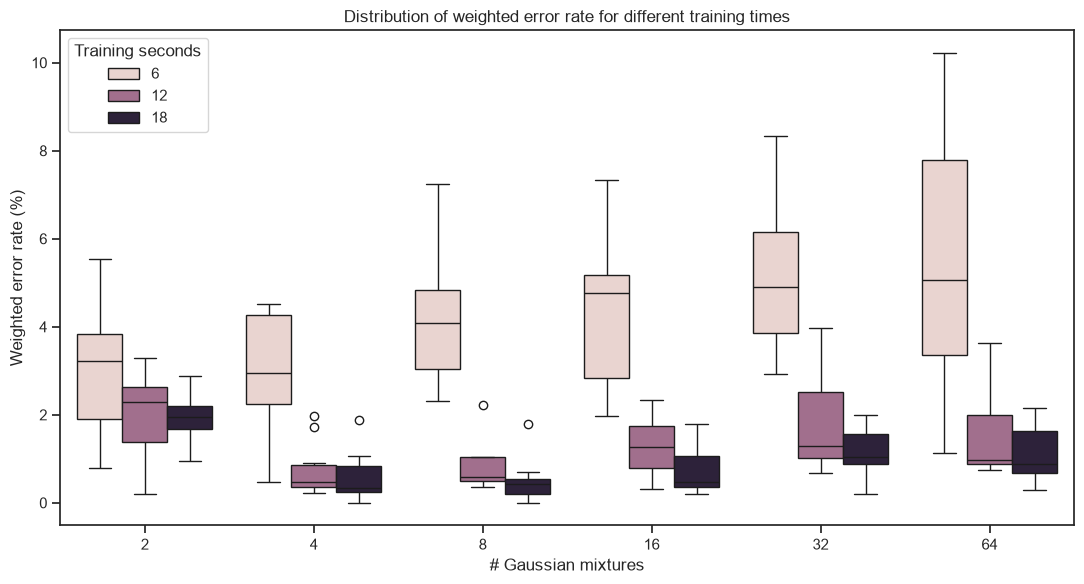

In [22]:
if RUN_FULL_EXPERIMENT:
    wer_summary = (
        wer_results
        .groupby(["training_seconds_target", "n_components"], as_index=False)
        .agg(WER_mean=("WER", "mean"), WER_std=("WER", "std"), WER_min=("WER", "min"), WER_max=("WER", "max"))
    )
    for col in ["WER_mean", "WER_std", "WER_min", "WER_max"]:
        wer_summary[col + "_percent"] = wer_summary[col] * 100

    display(wer_summary[[
        "training_seconds_target", "n_components", "WER_mean_percent", "WER_std_percent", "WER_min_percent", "WER_max_percent"
    ]].round(3))

    fig, ax = plt.subplots(figsize=(11, 6))
    sns.boxplot(
        data=wer_results,
        x="n_components",
        y="WER_percent",
        hue="training_seconds_target",
        ax=ax,
    )
    ax.set(
        title="Distribution of weighted error rate for different training times",
        xlabel="# Gaussian mixtures",
        ylabel="Weighted error rate (%)",
    )
    ax.legend(title="Training seconds")
    plt.tight_layout()
    plt.show()

## 12. Reproduce the structure of Table 2

The paper reports per-species error versus model order for the **12-second / 20 m-FCC** condition. The recovered species set differs, so this table is structurally comparable rather than numerically identical by design.

In [23]:
if RUN_FULL_EXPERIMENT:
    table2_replication = (
        per_species_results[per_species_results["training_seconds_target"] == 12]
        .groupby(["code", "species", "n_components"])["error_rate"]
        .mean()
        .mul(100)
        .unstack("n_components")
        .reindex(columns=N_COMPONENTS_GRID)
        .round(3)
    )
    table2_replication.columns = [f"M={m}" for m in table2_replication.columns]
    display(table2_replication)

,,M=2,M=4,M=8,M=16,M=32,M=64
code,species,,,,,,
f01,Boana alfaroi,0.000,0.000,0.000,0.000,0.000,0.000
f02,Dendropsophus bifurcus,11.129,2.538,2.539,3.099,3.238,2.793
f03,Boana cinerascens,6.844,3.550,3.285,3.621,3.887,3.956
f04,Pristimantis conspicillatus,0.000,0.128,0.446,1.403,0.639,0.702
f05,Leptodactylus discodactylus,0.197,0.000,0.000,0.033,0.033,0.000
f06,Osteocephalus fuscifacies,0.000,0.000,0.000,0.370,0.000,0.000
f07,Boana lanciformis,0.000,0.000,0.241,0.361,1.455,0.602
f08,Rhinella margaritifera,0.000,0.479,0.720,2.248,6.548,4.897
f10,Engystomops petersi,0.453,0.035,0.244,0.174,0.209,0.801


### Published Table 2 values for reference

The paper's nine-species experiment excludes `f06` and includes `f09`. The following values are included only as a transparent reference; this replication must not be forced to match them.

In [28]:
PAPER_TABLE2_PERCENT = pd.DataFrame(
    {
        "M=2":  [0.0, 9.4, 0.4, 0.5, 0.3, 7.8, 11.7, 4.7, 0.2],
        "M=4":  [0.0, 6.7, 0.2, 0.6, 0.2, 3.4, 6.1, 3.0, 0.0],
        "M=8":  [0.0, 2.7, 0.2, 0.3, 0.3, 1.8, 5.2, 3.7, 0.0],
        "M=16": [0.0, 0.8, 0.1, 0.3, 0.1, 1.6, 4.2, 3.0, 0.0],
        "M=32": [0.0, 0.9, 0.1, 0.3, 0.1, 1.3, 4.1, 3.4, 0.0],
        "M=64": [0.0, 0.8, 0.2, 0.3, 0.2, 1.6, 3.2, 3.0, 0.0],
    },
    index=["f01", "f02", "f03", "f04", "f05", "f07", "f08", "f09", "f10"],
)

PAPER_TABLE2_PERCENT.index.name = "code"
display(PAPER_TABLE2_PERCENT)

if RUN_FULL_EXPERIMENT:
    replication_by_code = table2_replication.reset_index(
        level="species",
        drop=True
    )

    # Align the paper table to all species available in the replication.
    # Species absent from Table 2 of the paper (e.g. f06) remain as NaN.
    paper_aligned = PAPER_TABLE2_PERCENT.reindex(replication_by_code.index)

    difference = (
        replication_by_code - paper_aligned
    ).round(3)

    print("Replication results:")
    display(replication_by_code)

    print("Replication minus paper, percentage points:")
    print("NaN indicates that the species was not reported in Paper Table 2.")
    display(difference)

,M=2,M=4,M=8,M=16,M=32,M=64
code,,,,,,
f01,0.0,0.0,0.0,0.0,0.0,0.0
f02,9.4,6.7,2.7,0.8,0.9,0.8
f03,0.4,0.2,0.2,0.1,0.1,0.2
f04,0.5,0.6,0.3,0.3,0.3,0.3
f05,0.3,0.2,0.3,0.1,0.1,0.2
f07,7.8,3.4,1.8,1.6,1.3,1.6
f08,11.7,6.1,5.2,4.2,4.1,3.2
f09,4.7,3.0,3.7,3.0,3.4,3.0
f10,0.2,0.0,0.0,0.0,0.0,0.0


Replication results:


,M=2,M=4,M=8,M=16,M=32,M=64
code,,,,,,
f01,0.000,0.000,0.000,0.000,0.000,0.000
f02,11.129,2.538,2.539,3.099,3.238,2.793
f03,6.844,3.550,3.285,3.621,3.887,3.956
f04,0.000,0.128,0.446,1.403,0.639,0.702
f05,0.197,0.000,0.000,0.033,0.033,0.000
f06,0.000,0.000,0.000,0.370,0.000,0.000
f07,0.000,0.000,0.241,0.361,1.455,0.602
f08,0.000,0.479,0.720,2.248,6.548,4.897
f10,0.453,0.035,0.244,0.174,0.209,0.801


Replication minus paper, percentage points:
NaN indicates that the species was not reported in Paper Table 2.


,M=2,M=4,M=8,M=16,M=32,M=64
code,,,,,,
f01,0.000,0.000,0.000,0.000,0.000,0.000
f02,1.729,-4.162,-0.161,2.299,2.338,1.993
f03,6.444,3.350,3.085,3.521,3.787,3.756
f04,-0.500,-0.472,0.146,1.103,0.339,0.402
f05,-0.103,-0.200,-0.300,-0.067,-0.067,-0.200
f06,NaN,NaN,NaN,NaN,NaN,NaN
f07,-7.800,-3.400,-1.559,-1.239,0.155,-0.998
f08,-11.700,-5.621,-4.480,-1.952,2.448,1.697
f10,0.253,0.035,0.244,0.174,0.209,0.801


## 13. Best average condition in the recovered corpus

The paper chose `M=64` because it minimized average error in its own experiment. This replication computes its own optimum rather than assuming the same result.

In [29]:
if RUN_FULL_EXPERIMENT:
    best = wer_summary.sort_values(["WER_mean", "training_seconds_target", "n_components"]).iloc[0]
    print(
        "Lowest mean WER in this replication:\n"
        f"  training duration : {int(best.training_seconds_target)} s\n"
        f"  components        : {int(best.n_components)}\n"
        f"  mean WER          : {best.WER_mean_percent:.3f}%\n"
        f"  std               : {best.WER_std_percent:.3f}%"
    )

Lowest mean WER in this replication:
  training duration : 18 s
  components        : 8
  mean WER          : 0.501%
  std               : 0.502%


## 14. Save experiment outputs

Temporary GMMs from the grid are not serialized. The experiment tables are saved so the analysis can be reproduced without retraining simply to inspect results.

In [30]:
if RUN_FULL_EXPERIMENT:
    RESULTS_DIR = PROCESSED_DIR / "gmm_parameter_investigation"
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    per_species_results.to_csv(RESULTS_DIR / "per_species_results.csv", index=False)
    wer_results.to_csv(RESULTS_DIR / "wer_by_repeat.csv", index=False)
    wer_summary.to_csv(RESULTS_DIR / "wer_summary.csv", index=False)
    table2_replication.to_csv(RESULTS_DIR / "table2_replication.csv")

    if STORE_CALL_PREDICTIONS:
        call_predictions.to_csv(RESULTS_DIR / "call_predictions.csv", index=False)

    print("Written to:", RESULTS_DIR)
    for path in sorted(RESULTS_DIR.iterdir()):
        print(f"  {path.name:<28} {path.stat().st_size / 1e6:>8.2f} MB")

Written to: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\gmm_parameter_investigation
  call_predictions.csv            15.42 MB
  per_species_results.csv          0.14 MB
  table2_replication.csv           0.00 MB
  wer_by_repeat.csv                0.01 MB
  wer_summary.csv                  0.00 MB


## 15. Conclusions and limitations

After execution, this notebook delivers the GMM parameter investigation needed before moving to detection:

1. complete-call reconstruction from the frame matrix;
2. leakage-free 6/12/18-second train selections;
3. one diagonal GMM per usable species;
4. call-level mean log-likelihood classification;
5. per-species error and macro-averaged WER;
6. ten repeated random selections for every duration/model-order combination;
7. a Figure 8-style WER distribution;
8. a Table 2-style per-species error table.

### Limitations

- The recovered species set differs from the paper because `f09` lacks enough labelled audio.
- The m-FCC front end inherits the filter-bank and frame-rate uncertainties documented in notebook 02.
- The paper's Figure 8 is labelled **12 MFCC** and Section 4.1 refers to 12-dimensional mel-cepstral vectors, while this notebook receives **20 m-FCC** from notebook 02. Its training-duration plot therefore reproduces the GMM protocol, not the exact Figure 8 feature configuration.
- The paper's “10-fold cross-validation with random segment selection” is underspecified. This notebook uses ten reproducible random call selections and labels that choice explicitly.
- Whole calls are selected until the duration target is reached or exceeded; the overshoot is stored.
- Scikit-learn uses a small covariance regularizer for numerical stability, which the article does not report.

### Scope boundary

This notebook stops at **frog-species identification and GMM parameter investigation**. The next stage is:

**hypothesized species → alternative-model likelihood → likelihood ratio → per-class ROC threshold → long-recording detections → presence/absence**.